# Incompressible flow, Poiseuille and boundaries

What does a pressure-driven channel benchmark verify, and which boundary choices determine its answer?

Fall 2024.


## Predict
This new code solves a reduced steady planar velocity BVP, not a full fluid system. Predict the direction and shape for a positive pressure-driving gradient. Distinguish speed, flow per width and total flow.

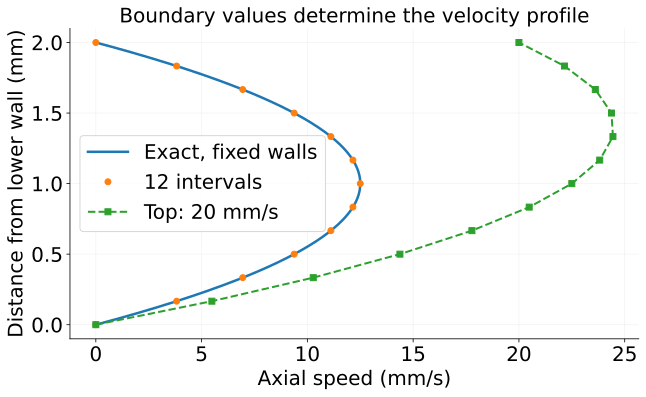

{'flux_per_width': 1.6550925925925924e-05,
 'exact_flux_per_width': 1.6666666666666667e-05,
 'max_profile_error': 6.071532165918825e-18,
 'max_algebraic_residual': 2.8189256484623115e-18}

In [1]:
import numpy as np
from demo import channel, run
from IPython.display import SVG, display
report=run()
display(SVG(filename="channel-profiles.svg"))
report["stationary"]

## Implement the guided quadrature
Use the trapezoidal formula to integrate the nodal profile. The supplied starter runs; rewrite its body as an explicit loop and compare. The default channel is a worked class example.

In [2]:
def my_flux(y,u):
    y=np.asarray(y);u=np.asarray(u)
    return np.sum(np.diff(y)*(u[:-1]+u[1:])/2)
r=channel(n=8)
np.testing.assert_allclose(my_flux(r["y"],r["u"]),r["flux_per_width"])
print("relative quadrature error",1-my_flux(r["y"],r["u"])/r["exact_flux_per_width"])

relative quadrature error 0.015624999999999889


## Run, modify and interpret
Change only the upper-wall speed, then only the gradient sign. Predict each result before execution. Verify the wall values and compare the profile against the supplied analytic expression.

{'top': 0.02} wall speeds [0.   0.02] profile error 1.0408340855860843e-17
{'G': -100} wall speeds [0. 0.] profile error 5.204170427930421e-18
{'G': 0, 'top': 0.02} wall speeds [0.   0.02] profile error 3.469446951953614e-18


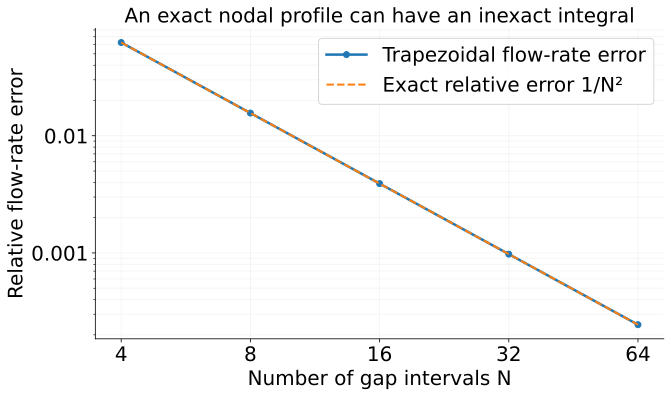

In [3]:
for options in [dict(top=.02),dict(G=-100),dict(G=0,top=.02)]:
    r=channel(n=16,**options)
    print(options,"wall speeds",r["u"][[0,-1]],"profile error",r["max_profile_error"])
display(SVG(filename="channel-flux-error.svg"))

## Reflect
Explain why the profile error is near roundoff while the integrated flow is inexact. List a boundary condition and a physical effect that this reduced benchmark does not test.